[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/10_first_qsar_model.ipynb)

# 10 · Your First QSAR Model: Predicting Aqueous Solubility

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~55 min*

QSAR (quantitative structure-activity/property relationship) models learn a mapping from
structure to a measured property. We predict **aqueous solubility (logS)** for the ESOL set, the same
data Delaney used in 2004 to build his ESOL equation from four descriptors.

**Learning objectives.** By the end of this notebook you will be able to:

- turn molecules into feature matrices (descriptors and fingerprints)
- train and evaluate a random forest regression model
- compare against simple baselines, including Delaney's original ESOL descriptors
- read parity plots, error metrics, and feature importances

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit', 'scikit-learn'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")
import warnings
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors, rdFingerprintGenerator
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

esol = pd.read_csv(f"{DATA_DIR}/esol_delaney.csv")
esol["mol"] = esol["smiles"].apply(Chem.MolFromSmiles)
y = esol["logS"].values
print(esol.shape)

(1128, 4)


## 1. Features

We build three feature sets:

1. **Delaney's four descriptors**: Crippen logP, molecular weight, rotatable bonds, and the aromatic proportion (aromatic atoms / heavy atoms).
2. **All RDKit 2D descriptors** (~200 numbers per molecule).
3. **Morgan fingerprints** (radius 2, 2,048 bits).

In [3]:
def delaney_features(m):
    aromatic = sum(a.GetIsAromatic() for a in m.GetAtoms()) / m.GetNumHeavyAtoms()
    return [Crippen.MolLogP(m), Descriptors.MolWt(m), rdMolDescriptors.CalcNumRotatableBonds(m), aromatic]

X_delaney = np.array([delaney_features(m) for m in esol["mol"]])

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    desc = pd.DataFrame([Descriptors.CalcMolDescriptors(m) for m in esol["mol"]])
desc = desc.replace([np.inf, -np.inf], np.nan)
desc = desc.loc[:, desc.notna().all() & (desc.std() > 0)]     # drop broken and constant columns
X_desc = desc.values

mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X_fp = np.array([mfpgen.GetFingerprintAsNumPy(m) for m in esol["mol"]])

print("Delaney:", X_delaney.shape, "| RDKit descriptors:", X_desc.shape, "| Morgan:", X_fp.shape)

Delaney: (1128, 4) | RDKit descriptors: (1128, 199) | Morgan: (1128, 2048)


## 2. Train/test split

We hold out 20 % of the molecules as a **test set** that the model never sees during training.
(Notebook 11 shows why a *random* split can be too optimistic.)

In [4]:
idx_train, idx_test = train_test_split(np.arange(len(esol)), test_size=0.2, random_state=42)
y_train, y_test = y[idx_train], y[idx_test]
print(len(idx_train), "training |", len(idx_test), "test molecules")

902 training | 226 test molecules


## 3. Baselines first

A model is only interesting if it beats simple alternatives:
- **mean predictor**: always predicts the training-set mean (R2 approximately 0 by construction);
- **linear regression on Delaney's four descriptors**: essentially refitting the original ESOL equation.

In [5]:
def evaluate(name, model, X):
    model.fit(X[idx_train], y_train)
    pred = model.predict(X[idx_test])
    return {"model": name,
            "R2": r2_score(y_test, pred),
            "RMSE": mean_squared_error(y_test, pred) ** 0.5,
            "MAE": mean_absolute_error(y_test, pred)}, pred

results, preds = [], {}
for name, model, X in [
    ("mean predictor", DummyRegressor(), X_delaney),
    ("linear, Delaney 4 descriptors", LinearRegression(), X_delaney),
]:
    r, p = evaluate(name, model, X); results.append(r); preds[name] = p
pd.DataFrame(results).round(3)

,model,R2,RMSE,MAE
0,mean predictor,-0.000,2.174,1.732
1,"linear, Delaney 4 descriptors",0.738,1.113,0.833


## 4. Random forests

A random forest averages many decision trees trained on bootstrap samples. It handles non-linear
effects, needs no feature scaling, and is a strong default for small QSAR datasets.

In [6]:
for name, X in [("RF, Delaney 4 descriptors", X_delaney),
                ("RF, RDKit descriptors", X_desc),
                ("RF, Morgan fingerprint", X_fp)]:
    rf = RandomForestRegressor(n_estimators=500, random_state=0, n_jobs=-1)
    r, p = evaluate(name, rf, X); results.append(r); preds[name] = p
summary = pd.DataFrame(results).set_index("model").round(3)
summary

,R2,RMSE,MAE
model,,,
mean predictor,-0.000,2.174,1.732
"linear, Delaney 4 descriptors",0.738,1.113,0.833
"RF, Delaney 4 descriptors",0.855,0.829,0.578
"RF, RDKit descriptors",0.883,0.743,0.504
"RF, Morgan fingerprint",0.709,1.172,0.882


## 5. Parity plot

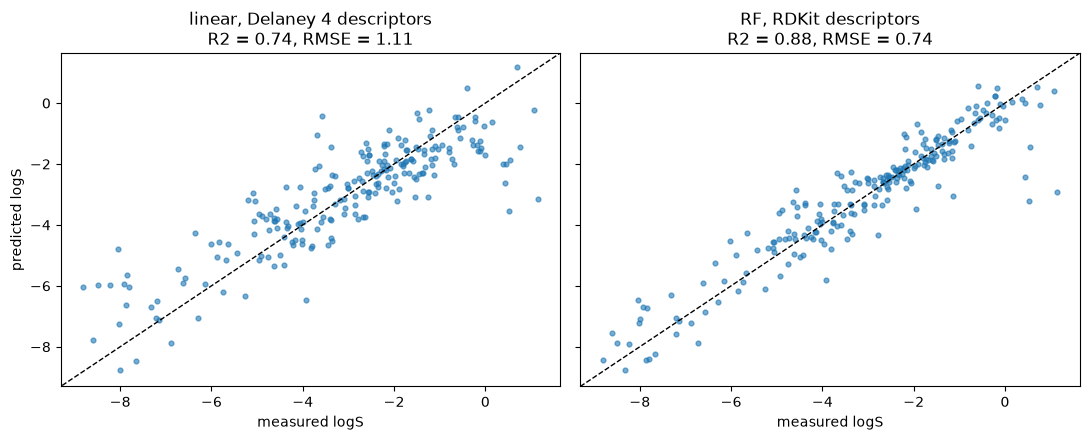

In [7]:
best = summary["R2"].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, ["linear, Delaney 4 descriptors", best]):
    p = preds[name]
    ax.scatter(y_test, p, s=12, alpha=0.6)
    lims = [min(y_test.min(), p.min()) - 0.5, max(y_test.max(), p.max()) + 0.5]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("measured logS")
    ax.set_title(f"{name}\nR2 = {summary.loc[name, 'R2']:.2f}, RMSE = {summary.loc[name, 'RMSE']:.2f}")
axes[0].set_ylabel("predicted logS")
plt.tight_layout(); plt.show()

## 6. Cross-validation: how stable is the score?

One split gives one number. 5-fold cross-validation gives five, and their spread.

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=0)
rf = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1)
scores = cross_val_score(rf, X_desc, y, cv=cv, scoring="r2")
print("R2 per fold:", scores.round(3))
print(f"mean +/- sd:   {scores.mean():.3f} +/- {scores.std():.3f}")

R2 per fold: [0.898 0.91  0.862 0.918 0.923]
mean +/- sd:   0.902 +/- 0.022


## 7. What did the model learn?

Impurity-based feature importances from the descriptor random forest. Expect lipophilicity and
size/aromaticity descriptors near the top, consistent with Delaney's equation.

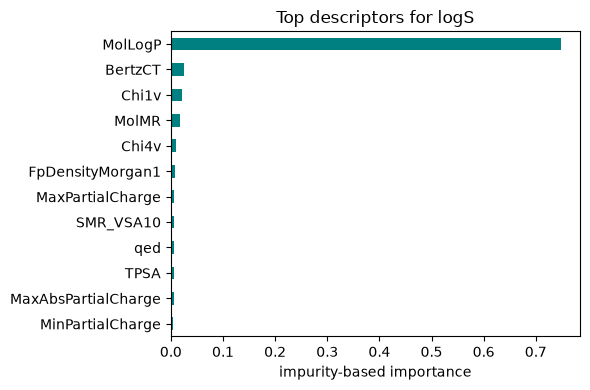

In [9]:
rf_desc = RandomForestRegressor(n_estimators=500, random_state=0, n_jobs=-1).fit(X_desc[idx_train], y_train)
imp = pd.Series(rf_desc.feature_importances_, index=desc.columns).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(6, 4))
imp[::-1].plot.barh(ax=ax, color="teal")
ax.set_xlabel("impurity-based importance"); ax.set_title("Top descriptors for logS")
plt.tight_layout(); plt.show()

## 8. Predicting new molecules

Predictions are only as good as the similarity of the new molecule to the training data (see Notebooks 08 and 11).

In [10]:
new = {"aspirin": "CC(=O)Oc1ccccc1C(=O)O",
       "paracetamol": "CC(=O)Nc1ccc(O)cc1",
       "ibuprofen": "CC(C)Cc1ccc(cc1)C(C)C(=O)O"}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    new_desc = pd.DataFrame([Descriptors.CalcMolDescriptors(Chem.MolFromSmiles(s)) for s in new.values()])[desc.columns]
pd.DataFrame({"predicted logS": rf_desc.predict(new_desc.values).round(2)}, index=list(new))

,predicted logS
aspirin,-1.96
paracetamol,-1.42
ibuprofen,-3.68


All three are carboxylic acids or close analogues, and Notebook 05 showed ESOL contains **no** carboxylic acids.
Treat the aspirin and ibuprofen predictions with particular caution.

### ✏️ Exercise 1

Train a `RandomForestRegressor` on Morgan fingerprints **with radius 3** (2,048 bits) and compare its test R2 with radius 2.

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
gen3 = rdFingerprintGenerator.GetMorganGenerator(radius=3, fpSize=2048)
X_fp3 = np.array([gen3.GetFingerprintAsNumPy(m) for m in esol["mol"]])
r3, _ = evaluate("RF, Morgan r=3", RandomForestRegressor(n_estimators=500, random_state=0, n_jobs=-1), X_fp3)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in r3.items()})
print("radius 2 R2:", summary.loc["RF, Morgan fingerprint", "R2"])
```

</details>

### ✏️ Exercise 2

Combine the RDKit descriptors and the Morgan fingerprint into one feature matrix (`np.hstack`) and evaluate a random forest on it.

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
X_comb = np.hstack([X_desc, X_fp])
rc, _ = evaluate("RF, descriptors + Morgan", RandomForestRegressor(n_estimators=500, random_state=0, n_jobs=-1), X_comb)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in rc.items()})
```

</details>

### ✏️ Exercise 3

Which 5 test molecules have the largest absolute error for the best model? Draw them with measured and predicted logS.

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
err = np.abs(preds[best] - y_test)
worst = np.argsort(err)[::-1][:5]
rows = esol.iloc[idx_test[worst]]
Draw.MolsToGridImage(list(rows["mol"]), molsPerRow=5, subImgSize=(200, 180),
                     legends=[f"{n[:14]}\nexp {e:.2f} / pred {p:.2f}" for n, e, p in
                              zip(rows.compound_id, y_test[worst], preds[best][worst])])
```

</details>

## Key takeaways

- Always compare against baselines; a 20-year-old four-descriptor linear model is a tough one.
- Report R2, RMSE, and MAE on a held-out test set, plus cross-validation spread.
- Feature importances are a sanity check, not a mechanism.

**Next:** [11 · Honest validation](11_honest_validation_splits.ipynb).